# ANÁLISE POR PACOTES DE SERVIÇO

Este notebook cria os pacotes de serviço (combinação de serviços contratados por cliente), liga cada cliente ao seu pacote e analisa churn, valor mensal e perda de receita por pacote.

**Onde estão os dados**
- Catálogo: hackaton_databricks, esquema tabelas_hackaton.
- Origem: history_tipada (5.634 clientes) e inference_tipada (1.409 clientes), do notebook Dicionário de Dados.
- Tabelas geradas: pacotes_servicos, history_pacotes, inference_pacotes, quadrantes_pacotes_valor, classificacao_pacotes, resumo_pacotes_history, pagamento_pacotes_history e precos_servicos.
- View temporária: base_pacotes, criada na Validação 2 (Parte 1/4). Vale só na sessão; se o cluster reiniciar, rodar essa célula de novo.

**Ordem das etapas**
1. pacotes_servicos: um código por pacote, juntando as duas bases.
2. history_pacotes e inference_pacotes: cada cliente com seu pacote e código.
3. Faixas de clientes por pacote e quadrantes clientes x churn, com gráfico.
4. Quadrantes valor médio x churn, com gráfico, e classificacao_pacotes.
5. Resumo e pagamento por pacote (history).
6. Validações 1 a 9, incluindo a estimativa de preço por serviço (precos_servicos) e a perda por churn.

**Aspectos**
- São 322 pacotes, juntando as informações de history e inference, já que a análise atua nas duas bases. Cada pacote recebe um código (P001, P002...), igual nas duas.
- Dentro do mesmo pacote, contrato, forma de pagamento e valor mensal podem variar.
- Churn só existe em history; as análises de churn usam só history, e pacotes que aparecem só em inference ficam fora delas.
- Gráficos e quadrantes usam pacotes com 30 clientes ou mais: o corte deixa o gráfico com poucos pontos, de leitura fácil, e cobre mais da metade dos clientes.
- Quadrantes cruzam churn com número de clientes ou com valor médio. As linhas de corte são a mediana de cada eixo e o churn geral de history.
- Perda por churn = soma do MonthlyCharges dos clientes com Churn = Yes, em R$ por mês.
- O valor mensal é a soma de um preço fixo por serviço. Dois métodos independentes chegam a esse resultado: a regressão (precos_servicos) e a comparação direta entre pacotes (Validação 7). Nenhum dos dois mostra desconto por combinação nem acréscimo por contratar um serviço sozinho.
- Valores monetários em R$.

**Limitações**
- qtd_clientes em pacotes_servicos conta linhas das duas bases juntas, não clientes distintos.
- O preço de um serviço sozinho só pôde ser comparado para PhoneService e DSL.

# VALIDAÇÕES

## Validação 1 – 30 pacotes concentram 54,6% dos clientes da history
- **Pergunta:** como os pacotes se distribuem por número de clientes, para decidir o corte dos gráficos?
- **Resultado:** dos 322 pacotes, 30 têm 30 clientes ou mais e reúnem 3.076 dos 5.634 clientes (54,6%). Por faixa: 4 pacotes com 1 cliente (4 clientes); 85 com 2 a 4 (256); 111 com 5 a 9 (770); 92 com 10 a 29 (1.528); 24 com 30 a 99 (1.285); 6 com 100 ou mais (1.791).
- **Decisão:** gráficos e quadrantes usam só os pacotes com 30 clientes ou mais. O corte deixa o gráfico com poucos pontos, de leitura fácil, e ainda cobre mais da metade dos clientes.

- **Decisão:** gráficos e quadrantes usam só os pacotes com 30 clientes ou mais.

## Validação 2 – Pacotes e churn: a leitura por pacote é válida
- **Pergunta:** cada pacote tem uma única combinação de TechSupport, OnlineSecurity, OnlineBackup e DeviceProtection entre seus clientes? Quais pacotes têm churn zero e quais têm maior churn?
- **Resultado:**
  - Parte 1: 322 pacotes, nenhum com serviços diferentes entre clientes.
  - Parte 2: 101 pacotes têm churn zero (522 clientes); 87 incluem TechSupport ou OnlineSecurity, 34 incluem os dois e 9 incluem os quatro serviços.
  - Parte 3: os 30 pacotes de maior churn têm valor médio de R$ 29,86 a R$ 100,07; 4 incluem TechSupport, 7 incluem TechSupport ou OnlineSecurity e 6 custam menos de R$ 50.
  - Parte 4: entre os pacotes com 30 clientes ou mais, os de maior churn são P188 (76,3%), P316 (71,7%) e P318 (71,4%).
- **Decisão:** a leitura por pacote é válida.

## Validação 3 – Entre os 10 pacotes mais caros, só os 4 primeiros têm churn baixo
- **Pergunta:** qual o churn dos 10 pacotes de maior valor médio (30 clientes ou mais) e se eles incluem suporte?
- **Resultado:** os 4 primeiros (P301, P276, P292 e P297) têm churn de 11,1% a 23,7% e incluem suporte. A partir do 5º (P272, 46,4%) o churn deixa de ser baixo.

## Validação 4 – Em P276 e P267, a igualdade entre mês a mês e churn é coincidência
- **Pergunta:** nos pacotes P276 e P267, o percentual de clientes mês a mês é igual ao de churn por coincidência de contagem ou por erro de cálculo na Validação 3?
- **Resultado:** os dois têm 18 clientes mês a mês e 18 com churn. O churn está distribuído entre os três contratos (P276: 7, 7 e 4; P267: 12, 4 e 2).
- **Decisão:** é coincidência de contagem; não há erro de cálculo.

## Validação 5 – Sem suporte, o churn é maior em todas as faixas de valor
- **Pergunta:** o valor mensal alto, sozinho, explica o churn, ou o que pesa é o valor mensal alto sem suporte?
- **Resultado:** em todas as faixas com os dois grupos, "Sem suporte" tem churn maior (por exemplo, 51,8% contra 21,9% na faixa de R$ 90 ou mais). Totais: sem suporte, 2.058 clientes e 1.011 com churn; com suporte, 2.343 e 404; sem internet, 1.233; total, 5.634.

## Validação 6 – Idosos não pagam menos que não idosos no mesmo pacote
- **Pergunta:** clientes idosos (SeniorCitizen = 1) pagam menos que os não idosos, ou seja, existe desconto para idosos?
- **Resultado:** no mesmo pacote (ponderado), idosos pagam R$ 80,01 e não idosos R$ 80,02 (diferença de -R$ 0,01). A diferença por tipo de internet (DSL, -6,0%) não se repete no mesmo pacote.
- **Decisão:** não há desconto por idade.

## Validação 7 – Cada serviço tem preço fixo: sem desconto em pacote e sem acréscimo por contratar sozinho
- **Pergunta:** o preço de um serviço muda conforme o pacote em que ele é contratado (desconto em pacote ou acréscimo por contratar sozinho)?
- **Resultado:**
  - Parte 1 (regressão): o valor mensal é explicado pela soma de um preço fixo por serviço (R² 0,9988; erro médio R$ 1,02; 7.043 clientes). PhoneService R$ 20, MultipleLines R$ 5, DSL R$ 25, Fiber optic R$ 50, OnlineSecurity, OnlineBackup, DeviceProtection e TechSupport R$ 5 cada, StreamingTV e StreamingMovies R$ 10 cada. A taxa base estimada é de -R$ 0,10, com intervalo de confiança que inclui zero (-R$ 0,20 a R$ 0,01): não há taxa base.
  - Parte 2 (comparação direta): PhoneService sozinho custa R$ 19,96 e somado a pacotes R$ 20,01 a R$ 20,06; DSL sozinho R$ 24,90 e somado R$ 25,00 a R$ 25,16. Entre os demais serviços, o preço somado varia até R$ 0,21 conforme o tamanho do pacote, exceto StreamingTV (R$ 9,86 a R$ 10,38).
- **Decisão:** os dados não mostram desconto por contratar em pacote nem acréscimo por contratar sozinho.
- **Limitação:** o "sozinho" de PhoneService e DSL vem de um pacote cada, e Fiber optic não aparece sozinho.

## Validação 8 – P130 tem a maior perda mensal por churn (cerca de R$ 7.400)
- **Pergunta:** quais pacotes com 30 clientes ou mais perdem mais e quais perdem menos receita mensal por churn?
- **Resultado:**
  - Maior perda: P130 (185 clientes, churn 56,8%), cerca de R$ 7.400 por mês; P259 (131, 59,5%), R$ 5.850; P318 (84, 71,4%), R$ 5.700; P272 (112, 46,4%), R$ 5.450; P263 (97, 54,6%), R$ 5.300; P316 (60, 71,7%), R$ 3.650; P188 (59, 76,3%), R$ 3.600, o maior churn; P279 (61, 54,1%), R$ 3.300.
  - Menor perda: de R$ 92,45 (P237) a R$ 747,95 (P155). P237 (68 clientes, churn 1,5%) é o pacote completo (9 serviços, valor médio R$ 89,98), com 1 cliente cancelado. P194 (280 clientes, 2,9%) é PhoneService + MultipleLines (valor médio R$ 24,97): muitos clientes, mas churn e ticket baixos. P292 (31 clientes, 16,1%) é Fiber optic com 8 serviços (valor médio R$ 110,09): o ticket alto compensa a perda baixa só em parte. P155 (30 clientes, 33,3%) é o único dos 8 com churn acima do geral (26,7%).

## Validação 9 – Os 8 pacotes de maior perda respondem por 35,8% da perda mensal por churn
- **Pergunta:** qual a perda mensal total por churn na history e quanto os 8 pacotes de maior perda (Validação 8) representam, em receita e em clientes cancelados?
- **Resultado:** a perda total é de R$ 112.242,90 por mês, com 1.504 clientes cancelados. Os 8 pacotes somam R$ 40.190,05 (35,8% da perda) e 469 cancelamentos (31,2%). A participação na perda é maior que nos cancelamentos.

In [0]:
%sql
-- ============================================================
-- Tabela de pacotes de serviços (history_tipada + inference_tipada)
-- ============================================================
-- O que faz: cria um código por pacote de serviços distinto, com quantidade de registros e estatísticas de MonthlyCharges.
-- Origem:    history_tipada, inference_tipada.
-- Saída:     pacotes_servicos (codigo_pacote, pacote_servicos, qtd_clientes, valor_minimo, valor_maximo, variacao_pct, valor_medio, contratos, metodos_pagamento).
-- Regras:    pacote montado aqui, pois as duas origens não têm a coluna: serviço = Yes; InternetService diferente de No.
--            UNION ALL das duas bases, um pacote por linha; o mesmo pacote tem o mesmo código nas duas.
--            Código P001, P002... em ordem alfabética do texto do pacote.
--            qtd_clientes conta linhas das duas bases juntas.
--            variacao_pct = (maior - menor) / menor, em %; variacao_pct e valor_medio com 2 casas.
--            contratos e metodos_pagamento: valores distintos, ordenados, separados por " | ".
-- ============================================================

CREATE OR REPLACE TABLE hackaton_databricks.tabelas_hackaton.pacotes_servicos AS
SELECT
  concat('P', lpad(CAST(row_number() OVER (ORDER BY pacote_servicos) AS STRING), 3, '0')) AS codigo_pacote,
  pacote_servicos,
  qtd_clientes,
  valor_minimo,
  valor_maximo,
  variacao_pct,
  valor_medio,
  contratos,
  metodos_pagamento
FROM (
  SELECT pacote_servicos, COUNT(*) AS qtd_clientes, MIN(MonthlyCharges) AS valor_minimo, MAX(MonthlyCharges) AS valor_maximo, ROUND(100.0 * (MAX(MonthlyCharges) - MIN(MonthlyCharges)) / MIN(MonthlyCharges), 2) AS variacao_pct, ROUND(AVG(MonthlyCharges), 2) AS valor_medio, concat_ws(' | ', sort_array(collect_set(Contract))) AS contratos, concat_ws(' | ', sort_array(collect_set(PaymentMethod))) AS metodos_pagamento
  FROM (
    SELECT COALESCE(NULLIF(concat_ws(', ',
      CASE WHEN PhoneService = 'Yes' THEN 'PhoneService' END,
      CASE WHEN MultipleLines = 'Yes' THEN 'MultipleLines' END,
      CASE WHEN InternetService <> 'No' THEN concat('InternetService ', InternetService) END,
      CASE WHEN OnlineSecurity = 'Yes' THEN 'OnlineSecurity' END,
      CASE WHEN OnlineBackup = 'Yes' THEN 'OnlineBackup' END,
      CASE WHEN DeviceProtection = 'Yes' THEN 'DeviceProtection' END,
      CASE WHEN TechSupport = 'Yes' THEN 'TechSupport' END,
      CASE WHEN StreamingTV = 'Yes' THEN 'StreamingTV' END,
      CASE WHEN StreamingMovies = 'Yes' THEN 'StreamingMovies' END
    ), ''), 'Nenhum') AS pacote_servicos,
    MonthlyCharges, Contract, PaymentMethod
    FROM hackaton_databricks.tabelas_hackaton.history_tipada
    UNION ALL
    SELECT COALESCE(NULLIF(concat_ws(', ',
      CASE WHEN PhoneService = 'Yes' THEN 'PhoneService' END,
      CASE WHEN MultipleLines = 'Yes' THEN 'MultipleLines' END,
      CASE WHEN InternetService <> 'No' THEN concat('InternetService ', InternetService) END,
      CASE WHEN OnlineSecurity = 'Yes' THEN 'OnlineSecurity' END,
      CASE WHEN OnlineBackup = 'Yes' THEN 'OnlineBackup' END,
      CASE WHEN DeviceProtection = 'Yes' THEN 'DeviceProtection' END,
      CASE WHEN TechSupport = 'Yes' THEN 'TechSupport' END,
      CASE WHEN StreamingTV = 'Yes' THEN 'StreamingTV' END,
      CASE WHEN StreamingMovies = 'Yes' THEN 'StreamingMovies' END
    ), ''), 'Nenhum') AS pacote_servicos,
    MonthlyCharges, Contract, PaymentMethod
    FROM hackaton_databricks.tabelas_hackaton.inference_tipada
  )
  GROUP BY pacote_servicos
);

SELECT * FROM hackaton_databricks.tabelas_hackaton.pacotes_servicos
ORDER BY codigo_pacote
LIMIT 30;

codigo_pacote,pacote_servicos,qtd_clientes,valor_minimo,valor_maximo,variacao_pct,valor_medio,contratos,metodos_pagamento
P001,InternetService DSL,80,23.45,26.05,11.09,24.90,Month-to-month | One year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check
P002,"InternetService DSL, DeviceProtection",11,29.10,30.40,4.47,29.78,Month-to-month | One year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check
P003,"InternetService DSL, DeviceProtection, StreamingMovies",6,39.50,41.15,4.18,40.18,Month-to-month,Bank transfer (automatic) | Credit card (automatic) | Electronic check
P004,"InternetService DSL, DeviceProtection, StreamingTV",7,38.10,41.60,9.19,39.81,Month-to-month | One year,Credit card (automatic) | Electronic check | Mailed check
P005,"InternetService DSL, DeviceProtection, StreamingTV, StreamingMovies",23,47.95,51.35,7.09,49.71,Month-to-month | One year,Bank transfer (automatic) | Credit card (automatic) | Electronic check
P006,"InternetService DSL, DeviceProtection, TechSupport",11,33.45,36.25,8.37,35.15,Month-to-month | One year | Two year,Credit card (automatic) | Electronic check | Mailed check
P007,"InternetService DSL, DeviceProtection, TechSupport, StreamingMovies",4,43.65,47.05,7.79,45.21,Month-to-month | One year | Two year,Credit card (automatic) | Electronic check
P008,"InternetService DSL, DeviceProtection, TechSupport, StreamingTV",3,44.45,45.40,2.14,44.90,Month-to-month,Credit card (automatic) | Electronic check
P009,"InternetService DSL, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",15,53.35,56.75,6.37,54.72,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check
P010,"InternetService DSL, OnlineBackup",31,28.45,31.65,11.25,30.04,Month-to-month | One year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check


In [0]:
%sql
-- ============================================================
-- Tabela history_pacotes (history_tipada + pacotes_servicos)
-- ============================================================
-- O que faz: acrescenta pacote_servicos e codigo_pacote às linhas da history_tipada.
-- Origem:    history_tipada, pacotes_servicos.
-- Saída:     history_pacotes (todas as colunas da history_tipada + pacote_servicos, codigo_pacote).
-- Regras:    pacote_servicos montado com o mesmo critério da pacotes_servicos: serviço = Yes; InternetService diferente de No.
--            codigo_pacote buscado em pacotes_servicos pelo texto do pacote (LEFT JOIN).
--            history_tipada não é alterada; a célula pode ser rodada mais de uma vez.
-- ============================================================

CREATE OR REPLACE TABLE hackaton_databricks.tabelas_hackaton.history_pacotes AS
WITH base AS (
  SELECT
    t.*,
    COALESCE(NULLIF(concat_ws(', ',
      CASE WHEN PhoneService = 'Yes' THEN 'PhoneService' END,
      CASE WHEN MultipleLines = 'Yes' THEN 'MultipleLines' END,
      CASE WHEN InternetService <> 'No' THEN concat('InternetService ', InternetService) END,
      CASE WHEN OnlineSecurity = 'Yes' THEN 'OnlineSecurity' END,
      CASE WHEN OnlineBackup = 'Yes' THEN 'OnlineBackup' END,
      CASE WHEN DeviceProtection = 'Yes' THEN 'DeviceProtection' END,
      CASE WHEN TechSupport = 'Yes' THEN 'TechSupport' END,
      CASE WHEN StreamingTV = 'Yes' THEN 'StreamingTV' END,
      CASE WHEN StreamingMovies = 'Yes' THEN 'StreamingMovies' END
    ), ''), 'Nenhum') AS pacote_servicos
  FROM hackaton_databricks.tabelas_hackaton.history_tipada t
)
SELECT b.*, p.codigo_pacote
FROM base b
LEFT JOIN hackaton_databricks.tabelas_hackaton.pacotes_servicos p
  ON b.pacote_servicos = p.pacote_servicos;

SELECT * FROM hackaton_databricks.tabelas_hackaton.history_pacotes LIMIT 30;

customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome,pacote_servicos,codigo_pacote
4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,Yes,Yes,Yes,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,"I have been a customer with this internet provider for over four years now and I have been satisfied with the service. The DSL internet is reliable and I have had no issues with connectivity. The monthly charges of $68.75 are reasonable for the service I receive. I appreciate the convenience of paying with electronic check. Overall, I am happy with my experience and have no plans to switch providers.",6532,"PhoneService, InternetService DSL, OnlineBackup, DeviceProtection, TechSupport, StreamingTV",P082
6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,"I've been a customer with this company for over 2 and a half years now, and unfortunately I have decided to churn. The DSL internet service was reliable for the most part, but the monthly charges of $73.9 were a bit steep for the quality of service I was receiving. Additionally, having to mail in a check for payment was inconvenient and outdated. I ultimately decided to switch to a different provider that offered better value and more modern payment options.",7634,"PhoneService, InternetService DSL, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",P074
2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,"I have been a customer with this company for 22 months now and I have been satisfied with the service. I have not experienced any issues with billing or service interruptions. The monthly charges are affordable at $20.05 and I appreciate being able to pay by mailing a check. The lack of internet service is not a problem for me as I do not require it. Overall, I am happy with my experience as a customer and have no complaints.",3628,PhoneService,P065
5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,"I have been a customer with this internet provider for 28 months now and I have been very satisfied with the service. The monthly charges are reasonable at $35.9 and I appreciate the convenience of paying with electronic check. The DSL internet service has been reliable and I have not experienced any issues with connectivity. Overall, I am happy with my experience and have no plans to switch providers.",7851,"InternetService DSL, StreamingTV",P059
9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,"I have been using the fiber optic internet service for the past 2 months and I am very satisfied with the speed and reliability. The monthly charges of $70.3 are reasonable for the quality of service I am receiving. The electronic check payment method is convenient and hassle-free. Overall, I have had a positive experience with the service and have no plans to switch providers.",1691,"PhoneService, InternetService Fiber optic",P130
6797-LNAQX,Male,0,Yes,Yes,70,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Two year,No,Bank transfer (automatic),98.30,6859.50,Yes,"I have been a customer with this company for 70 months and initially signed up for a two-year contract. I have been using their fiber optic internet service and have been satisfied with the speed and reliability. However, I recently decided to churn because I found a better deal with another provider. The monthly charges of $98.3 were reasonable for the service I received. I appreciated the convenience of automatic bank transfers for payment. Overall, my experienc

In [0]:
%sql
-- ============================================================
-- Tabela inference_pacotes (inference_tipada + pacotes_servicos)
-- ============================================================
-- O que faz: acrescenta pacote_servicos e codigo_pacote às linhas da inference_tipada.
-- Origem:    inference_tipada, pacotes_servicos.
-- Saída:     inference_pacotes (todas as colunas da inference_tipada + pacote_servicos, codigo_pacote).
-- Regras:    pacote_servicos montado com o mesmo critério da pacotes_servicos: serviço = Yes; InternetService diferente de No.
--            codigo_pacote buscado em pacotes_servicos pelo texto do pacote (LEFT JOIN).
--            inference_tipada não é alterada; a célula pode ser rodada mais de uma vez.
-- ============================================================

CREATE OR REPLACE TABLE hackaton_databricks.tabelas_hackaton.inference_pacotes AS
WITH base AS (
  SELECT
    t.*,
    COALESCE(NULLIF(concat_ws(', ',
      CASE WHEN PhoneService = 'Yes' THEN 'PhoneService' END,
      CASE WHEN MultipleLines = 'Yes' THEN 'MultipleLines' END,
      CASE WHEN InternetService <> 'No' THEN concat('InternetService ', InternetService) END,
      CASE WHEN OnlineSecurity = 'Yes' THEN 'OnlineSecurity' END,
      CASE WHEN OnlineBackup = 'Yes' THEN 'OnlineBackup' END,
      CASE WHEN DeviceProtection = 'Yes' THEN 'DeviceProtection' END,
      CASE WHEN TechSupport = 'Yes' THEN 'TechSupport' END,
      CASE WHEN StreamingTV = 'Yes' THEN 'StreamingTV' END,
      CASE WHEN StreamingMovies = 'Yes' THEN 'StreamingMovies' END
    ), ''), 'Nenhum') AS pacote_servicos
  FROM hackaton_databricks.tabelas_hackaton.inference_tipada t
)
SELECT b.*, p.codigo_pacote
FROM base b
LEFT JOIN hackaton_databricks.tabelas_hackaton.pacotes_servicos p
  ON b.pacote_servicos = p.pacote_servicos;

SELECT * FROM hackaton_databricks.tabelas_hackaton.inference_pacotes LIMIT 20;


customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,CustomerFeedback,MonthlyIncome,pacote_servicos,codigo_pacote
4226-KKDON,Male,0,No,No,8,Yes,No,DSL,No,Yes,No,Yes,Yes,No,Month-to-month,Yes,Electronic check,66.65,520.95,I have been a customer with this DSL provider for 8 months now and I am overall satisfied with the service. The monthly charges are reasonable at $66.65 and I appreciate the convenience of the month-to-month contract. The internet service has been reliable and I have not experienced any issues with connectivity. Using electronic check as my payment method has been smooth and hassle-free. I have not experienced any reason to consider switching providers at this time.,1361,"PhoneService, InternetService DSL, OnlineBackup, TechSupport, StreamingTV",P089
8838-GPHZP,Female,0,No,No,63,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Mailed check,20.60,1298.70,"I have been a customer with this company for over 5 years and have been satisfied with their service. Even though I do not have internet service with them, I find their monthly charges to be very reasonable at $20.6. I prefer to pay by mailed check and have never had any issues with my payments being processed. Overall, I have had a positive experience with this company and have no plans to switch to another provider.",3850,PhoneService,P065
0320-JDNQG,Male,0,Yes,Yes,23,Yes,No,Fiber optic,Yes,No,No,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,99.85,2331.30,"I have been a customer with this fiber optic internet service provider for 23 months on a month-to-month contract. The monthly charges of $99.85 are reasonable for the high-speed internet I receive. However, I recently decided to cancel my service due to moving to a new area where this provider is not available. The process of cancelling was smooth and easy, and I appreciated being able to pay with electronic check. Overall, I was satisfied with the service during my time as a customer.",2736,"PhoneService, InternetService Fiber optic, OnlineSecurity, TechSupport, StreamingTV, StreamingMovies",P186
4837-PZTIC,Female,0,No,No,47,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,Two year,No,Mailed check,41.90,null,"I have been a loyal customer for almost 4 years now and have been satisfied with the DSL internet service provided by this company. The monthly charges are reasonable at $41.9 and I appreciate being able to pay by mailing a check. I have not experienced any issues with my service and have no plans to churn in the near future. Overall, I am happy with the service provided.",1139,"InternetService DSL, OnlineSecurity, DeviceProtection, TechSupport",P031
7748-UMTRK,Female,1,No,Yes,30,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,101.30,2974.50,"I have been a customer with this company for 30 months on a month-to-month contract with no issues of churn. I am very satisfied with the fiber optic internet service provided, as it is reliable and fast. The monthly charges of $101.30 are reasonable for the quality of service I receive. I appreciate the convenience of paying with an electronic check. Overall, I am happy with my experience and would recommend this company to others.",5211,"PhoneService, MultipleLines, InternetService Fiber optic, TechSupport, StreamingTV, StreamingMovies",P322
0823-HSCDJ,Male,1,No,No,52,No,No phone service,DSL,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,49.15,2550.90,"I was a customer with this company for over four years on a month-to-month contract with DSL internet service. The monthly charges were reasonable at $49.15. However, I ultimately decided to churn and cancel my service. The service itself was reliable, but I found better deals with oth

In [0]:
%sql
-- ============================================================
-- Validação 1 – Pacotes por faixa de nº de clientes (history_pacotes)
-- ============================================================
-- O que faz: conta quantos pacotes caem em cada faixa de número de clientes e soma os clientes de cada faixa.
-- Origem:    history_pacotes.
-- Saída:     consulta com faixa, pacotes e clientes (nada é gravado).
-- Regras:    clientes = linhas da history_pacotes por codigo_pacote.
--            Faixas: 1 cliente; 2 a 4; 5 a 9; 10 a 29; 30 a 99; 100 ou mais.
--            Serve para decidir o corte do gráfico; a soma de clientes deve fechar com o total de linhas da history_pacotes.
-- ============================================================

SELECT faixa, COUNT(*) AS pacotes, SUM(clientes) AS clientes
FROM (
  SELECT
    codigo_pacote,
    COUNT(*) AS clientes,
    CASE WHEN COUNT(*) = 1 THEN '1) 1 cliente'
         WHEN COUNT(*) < 5 THEN '2) 2 a 4'
         WHEN COUNT(*) < 10 THEN '3) 5 a 9'
         WHEN COUNT(*) < 30 THEN '4) 10 a 29'
         WHEN COUNT(*) < 100 THEN '5) 30 a 99'
         ELSE '6) 100 ou mais' END AS faixa
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
  GROUP BY codigo_pacote
)
GROUP BY faixa
ORDER BY faixa;

faixa,pacotes,clientes
1) 1 cliente,4,4
2) 2 a 4,85,256
3) 5 a 9,111,770
4) 10 a 29,92,1528
5) 30 a 99,24,1285
6) 100 ou mais,6,1791


In [0]:
%sql
-- ============================================================
-- Quadrantes por pacote de serviços (history_pacotes)
-- ============================================================
-- O que faz: classifica os pacotes com 30 ou mais clientes em quadrantes de adesão e churn, para o gráfico de quadrantes.
-- Origem:    history_pacotes.
-- Saída:     consulta com codigo_pacote, pacote_servicos, clientes, churn, taxa_churn_pct, contratos, metodos_pagamento, mediana_clientes, 
--            churn_geral_pct, quadrante (nada é gravado).
-- Regras:    churn = clientes com Churn = Yes; taxa_churn_pct = churn / clientes, em %, com 1 casa.
--            contratos e metodos_pagamento: valores distintos dos clientes do pacote, ordenados, separados por " | ".
--            Alta adesão = clientes >= mediana de clientes dos pacotes do gráfico (30 ou mais clientes).
--            Alto churn = taxa_churn_pct >= churn_geral_pct, calculado sobre todos os 5634 clientes da history_pacotes, com 1 casa.
--            Críticos: alta adesão e alto churn | Atenção: baixa adesão e alto churn.
--            Consolidados: alta adesão e baixo churn | Oportunidades: baixa adesão e baixo churn.
-- ============================================================


WITH pacotes AS (
  SELECT
    codigo_pacote,
    pacote_servicos,
    COUNT(*) AS clientes,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churn,
    ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taxa_churn_pct,
    concat_ws(' | ', sort_array(collect_set(Contract))) AS contratos,
    concat_ws(' | ', sort_array(collect_set(PaymentMethod))) AS metodos_pagamento
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
  GROUP BY codigo_pacote, pacote_servicos
  HAVING COUNT(*) >= 30
),
geral AS (
  SELECT ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS churn_geral_pct
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
),
mediana AS (
  SELECT percentile(clientes, 0.5) AS mediana_clientes FROM pacotes
)
SELECT
  p.*,
  m.mediana_clientes,
  g.churn_geral_pct,
  CASE WHEN p.clientes >= m.mediana_clientes AND p.taxa_churn_pct >= g.churn_geral_pct THEN 'Críticos'
       WHEN p.clientes <  m.mediana_clientes AND p.taxa_churn_pct >= g.churn_geral_pct THEN 'Atenção'
       WHEN p.clientes >= m.mediana_clientes THEN 'Consolidados'
       ELSE 'Oportunidades' END AS quadrante
FROM pacotes p
CROSS JOIN geral g
CROSS JOIN mediana m
ORDER BY p.clientes DESC;


codigo_pacote,pacote_servicos,clientes,churn,taxa_churn_pct,contratos,metodos_pagamento,mediana_clientes,churn_geral_pct,quadrante
P065,PhoneService,953,81,8.5,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,26.7,Consolidados
P194,"PhoneService, MultipleLines",280,8,2.9,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,26.7,Consolidados
P130,"PhoneService, InternetService Fiber optic",185,105,56.8,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,26.7,Críticos
P259,"PhoneService, MultipleLines, InternetService Fiber optic",131,78,59.5,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,26.7,Críticos
P066,"PhoneService, InternetService DSL",130,52,40.0,Month-to-month | One year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,26.7,Críticos
P272,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, DeviceProtection, StreamingTV, StreamingMovies",112,52,46.4,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,26.7,Críticos
P263,"PhoneService, MultipleLines, InternetService Fiber optic, DeviceProtection, StreamingTV, StreamingMovies",97,53,54.6,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check,56.0,26.7,Críticos
P301,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",90,10,11.1,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,26.7,Consolidados
P318,"PhoneService, MultipleLines, InternetService Fiber optic, StreamingTV, StreamingMovies",84,60,71.4,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,26.7,Críticos
P276,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",76,18,23.7,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,26.7,Consolidados


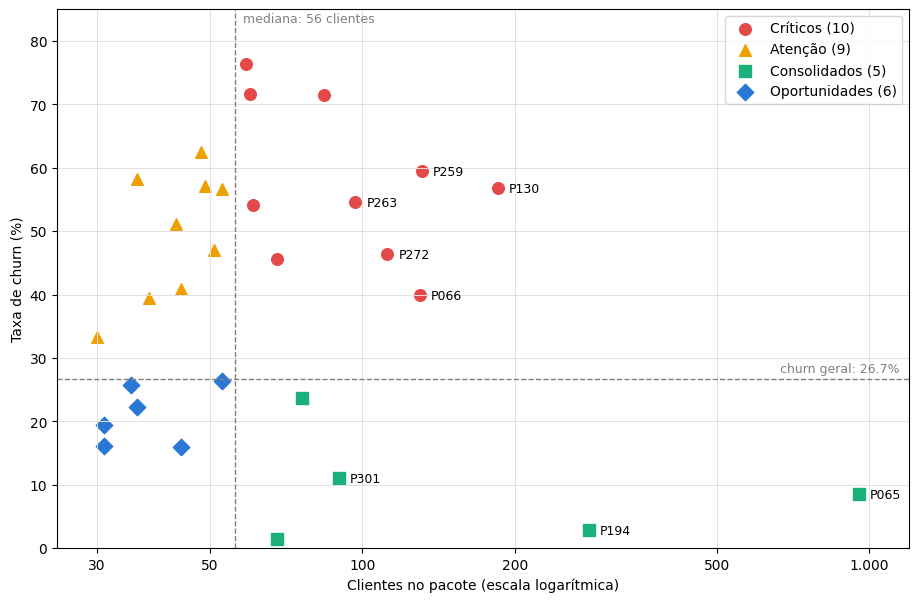

In [0]:
%python
%python
# ============================================================
# Gráfico de quadrantes dos pacotes de serviços (history_pacotes)
# ============================================================
# O que faz: plota os pacotes com 30 ou mais clientes por número de clientes e taxa de churn, separados em quadrantes.
# Origem:    history_pacotes.
# Saída:     gráfico de dispersão (nada é gravado).
# Regras:    eixo X = clientes no pacote, em escala logarítmica; eixo Y = taxa de churn (%).
#            Quadrantes calculados na própria célula, com o mesmo critério da consulta de quadrantes:
#            alta adesão = clientes >= mediana dos pacotes do gráfico; alto churn = taxa >= churn geral da history_pacotes.
#            Linhas tracejadas: mediana de clientes e churn geral.
#            Código do pacote escrito só nos pacotes com 90 ou mais clientes.
#            A legenda mostra a quantidade de pacotes de cada quadrante.
#            Limites dos eixos fixos (X de 25 a 1.200; Y de 0 a 85) e rótulos das linhas em posição fixa.
# ============================================================

import matplotlib.pyplot as plt

df = spark.sql("""
WITH pacotes AS (
  SELECT
    codigo_pacote,
    COUNT(*) AS clientes,
    ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taxa_churn_pct
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
  GROUP BY codigo_pacote
  HAVING COUNT(*) >= 30
),
geral AS (
  SELECT ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS churn_geral_pct
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
),
mediana AS (
  SELECT percentile(clientes, 0.5) AS mediana_clientes FROM pacotes
)
SELECT
  p.codigo_pacote, p.clientes, p.taxa_churn_pct, m.mediana_clientes, g.churn_geral_pct,
  CASE WHEN p.clientes >= m.mediana_clientes AND p.taxa_churn_pct >= g.churn_geral_pct THEN 'Críticos'
       WHEN p.clientes <  m.mediana_clientes AND p.taxa_churn_pct >= g.churn_geral_pct THEN 'Atenção'
       WHEN p.clientes >= m.mediana_clientes THEN 'Consolidados'
       ELSE 'Oportunidades' END AS quadrante
FROM pacotes p
CROSS JOIN geral g
CROSS JOIN mediana m
""").toPandas()

mediana = float(df["mediana_clientes"].iloc[0])
churn_geral = float(df["churn_geral_pct"].iloc[0])

estilos = {
    "Críticos": ("#e34948", "o"),
    "Atenção": ("#eda100", "^"),
    "Consolidados": ("#1baf7a", "s"),
    "Oportunidades": ("#2a78d6", "D"),
}

fig, ax = plt.subplots(figsize=(11, 7))
for quadrante, (cor, marcador) in estilos.items():
    d = df[df["quadrante"] == quadrante]
    ax.scatter(d["clientes"], d["taxa_churn_pct"], c=cor, marker=marcador, s=70,
               label=f"{quadrante} ({len(d)})")

ax.axvline(mediana, color="gray", linestyle="--", linewidth=1)
ax.axhline(churn_geral, color="gray", linestyle="--", linewidth=1)
ax.text(mediana * 1.04, 83, f"mediana: {mediana:g} clientes", color="gray", fontsize=9)
ax.text(1150, churn_geral + 1, f"churn geral: {churn_geral:g}%", color="gray", fontsize=9, ha="right")

for _, r in df[df["clientes"] >= 90].iterrows():
    ax.annotate(r["codigo_pacote"], (r["clientes"], r["taxa_churn_pct"]),
                textcoords="offset points", xytext=(8, -3), fontsize=9)

ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks([30, 50, 100, 200, 500, 1000])
ax.set_xticklabels(["30", "50", "100", "200", "500", "1.000"])
ax.set_xlim(25, 1200)
ax.set_ylim(0, 85)
ax.set_xlabel("Clientes no pacote (escala logarítmica)")
ax.set_ylabel("Taxa de churn (%)")
ax.grid(color="#e1e0d9", linewidth=0.7)
ax.legend(loc="upper right")
plt.show()

In [0]:
%sql
-- ============================================================
-- Quadrantes por valor médio do pacote (history_pacotes)
-- ============================================================
-- O que faz: classifica os pacotes com 30 ou mais clientes por valor médio e taxa de churn, em quadrantes.
-- Origem:    history_pacotes.
-- Saída:     quadrantes_pacotes_valor (codigo_pacote, pacote_servicos, clientes, churn, taxa_churn_pct, contratos, metodos_pagamento, valor_medio, mediana_valor, churn_geral_pct, quadrante).
-- Regras:    só history, porque o churn só existe nela; corte de 30 ou mais clientes por pacote.
--            churn = clientes com Churn = Yes; taxa_churn_pct = churn / clientes, em %, com 1 casa.
--            valor_medio = média do MonthlyCharges do pacote, com 2 casas.
--            mediana_valor = mediana dos valor_medio dos pacotes da tabela.
--            churn_geral_pct = taxa de churn de todos os clientes da history_pacotes, com 1 casa.
--            Caro = valor_medio >= mediana_valor; alto churn = taxa_churn_pct >= churn_geral_pct (comparação com valores já arredondados).
--            Quadrantes: Caro e alto churn | Barato e alto churn | Caro e baixo churn | Barato e baixo churn.
--            contratos e metodos_pagamento: valores distintos dos clientes do pacote, ordenados, separados por " | ".
-- ============================================================

CREATE OR REPLACE TABLE hackaton_databricks.tabelas_hackaton.quadrantes_pacotes_valor AS
WITH pacotes AS (
  SELECT
    codigo_pacote,
    pacote_servicos,
    COUNT(*) AS clientes,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churn,
    CAST(ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS DOUBLE) AS taxa_churn_pct,
    concat_ws(' | ', sort_array(collect_set(Contract))) AS contratos,
    concat_ws(' | ', sort_array(collect_set(PaymentMethod))) AS metodos_pagamento,
    CAST(ROUND(AVG(MonthlyCharges), 2) AS DOUBLE) AS valor_medio
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
  GROUP BY codigo_pacote, pacote_servicos
  HAVING COUNT(*) >= 30
),
geral AS (
  SELECT CAST(ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS DOUBLE) AS churn_geral_pct
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
),
mediana AS (
  SELECT percentile(valor_medio, 0.5) AS mediana_valor FROM pacotes
)
SELECT
  p.*,
  m.mediana_valor,
  g.churn_geral_pct,
  CASE WHEN p.valor_medio >= m.mediana_valor AND p.taxa_churn_pct >= g.churn_geral_pct THEN 'Caro e alto churn'
       WHEN p.valor_medio <  m.mediana_valor AND p.taxa_churn_pct >= g.churn_geral_pct THEN 'Barato e alto churn'
       WHEN p.valor_medio >= m.mediana_valor THEN 'Caro e baixo churn'
       ELSE 'Barato e baixo churn' END AS quadrante
FROM pacotes p
CROSS JOIN geral g
CROSS JOIN mediana m;

SELECT * FROM hackaton_databricks.tabelas_hackaton.quadrantes_pacotes_valor
ORDER BY valor_medio DESC;

codigo_pacote,pacote_servicos,clientes,churn,taxa_churn_pct,contratos,metodos_pagamento,valor_medio,mediana_valor,churn_geral_pct,quadrante
P301,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",90,10,11.1,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,115.09,80.05,26.7,Caro e baixo churn
P276,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",76,18,23.7,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,110.1,80.05,26.7,Caro e baixo churn
P292,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineSecurity, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",31,5,16.1,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,110.09,80.05,26.7,Caro e baixo churn
P297,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineSecurity, OnlineBackup, DeviceProtection, StreamingTV, StreamingMovies",44,7,15.9,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,109.72,80.05,26.7,Caro e baixo churn
P272,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, DeviceProtection, StreamingTV, StreamingMovies",112,52,46.4,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,104.88,80.05,26.7,Caro e alto churn
P267,"PhoneService, MultipleLines, InternetService Fiber optic, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",44,18,40.9,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,104.62,80.05,26.7,Caro e alto churn
P263,"PhoneService, MultipleLines, InternetService Fiber optic, DeviceProtection, StreamingTV, StreamingMovies",97,53,54.6,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check,100.07,80.05,26.7,Caro e alto churn
P279,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, StreamingTV, StreamingMovies",61,33,54.1,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,99.79,80.05,26.7,Caro e alto churn
P134,"PhoneService, InternetService Fiber optic, DeviceProtection, StreamingTV, StreamingMovies",36,21,58.3,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,95.06,80.05,26.7,Caro e alto churn
P318,"PhoneService, MultipleLines, InternetService Fiber optic, StreamingTV, StreamingMovies",84,60,71.4,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,94.89,80.05,26.7,Caro e alto churn


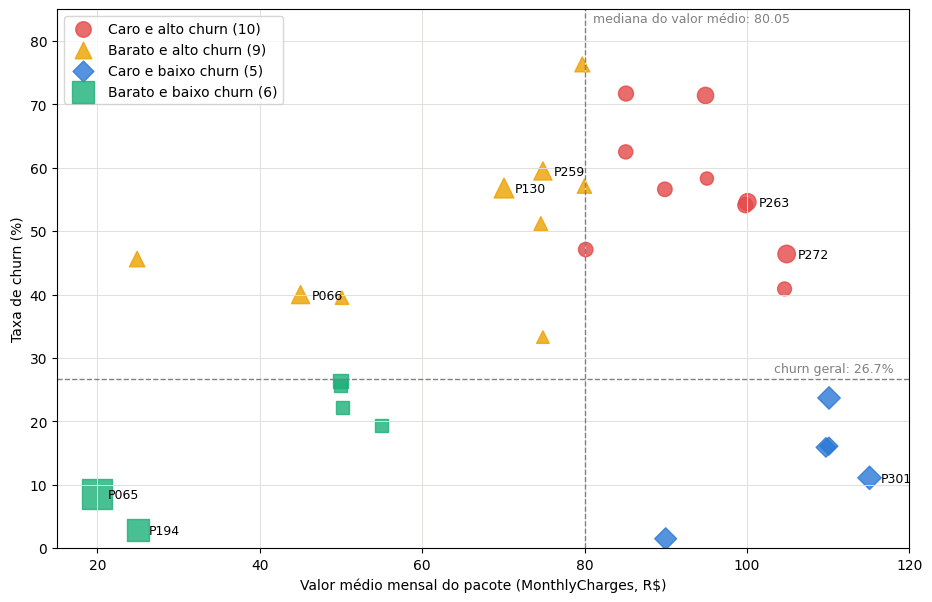

In [0]:
%python
# ============================================================
# Gráfico de quadrantes dos pacotes de serviços (history_pacotes)
# ============================================================
# O que faz: plota os pacotes com 30 ou mais clientes por número de clientes e taxa de churn, separados em quadrantes.
# Origem:    history_pacotes.
# Saída:     gráfico de dispersão (nada é gravado).
# Regras:    eixo X = clientes no pacote, em escala logarítmica; eixo Y = taxa de churn (%).
#            Quadrantes calculados na própria célula, com o mesmo critério da consulta de quadrantes:
#            alta adesão = clientes >= mediana dos pacotes do gráfico; alto churn = taxa >= churn geral da history_pacotes.
#            Linhas tracejadas: mediana de clientes e churn geral.
#            Código do pacote escrito só nos pacotes com 90 ou mais clientes.
#            A legenda mostra a quantidade de pacotes de cada quadrante.
# ============================================================
import matplotlib.pyplot as plt

df = spark.sql("""
WITH pacotes AS (
  SELECT
    codigo_pacote,
    COUNT(*) AS clientes,
    CAST(ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS DOUBLE) AS taxa_churn_pct,
    CAST(ROUND(AVG(MonthlyCharges), 2) AS DOUBLE) AS valor_medio
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
  GROUP BY codigo_pacote
  HAVING COUNT(*) >= 30
),
geral AS (
  SELECT CAST(ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS DOUBLE) AS churn_geral_pct
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
),
mediana AS (
  SELECT percentile(valor_medio, 0.5) AS mediana_valor FROM pacotes
)
SELECT
  p.codigo_pacote, p.clientes, p.taxa_churn_pct, p.valor_medio, m.mediana_valor, g.churn_geral_pct,
  CASE WHEN p.valor_medio >= m.mediana_valor AND p.taxa_churn_pct >= g.churn_geral_pct THEN 'Caro e alto churn'
       WHEN p.valor_medio <  m.mediana_valor AND p.taxa_churn_pct >= g.churn_geral_pct THEN 'Barato e alto churn'
       WHEN p.valor_medio >= m.mediana_valor THEN 'Caro e baixo churn'
       ELSE 'Barato e baixo churn' END AS quadrante
FROM pacotes p
CROSS JOIN geral g
CROSS JOIN mediana m
""").toPandas()

mediana = float(df["mediana_valor"].iloc[0])
churn_geral = float(df["churn_geral_pct"].iloc[0])

estilos = {
    "Caro e alto churn": ("#e34948", "o"),
    "Barato e alto churn": ("#eda100", "^"),
    "Caro e baixo churn": ("#2a78d6", "D"),
    "Barato e baixo churn": ("#1baf7a", "s"),
}

fig, ax = plt.subplots(figsize=(11, 7))
for quadrante, (cor, marcador) in estilos.items():
    d = df[df["quadrante"] == quadrante]
    ax.scatter(d["valor_medio"], d["taxa_churn_pct"], c=cor, marker=marcador, s=15 * d["clientes"] ** 0.5, alpha=0.8, label=f"{quadrante} ({len(d)})")

ax.axvline(mediana, color="gray", linestyle="--", linewidth=1)
ax.axhline(churn_geral, color="gray", linestyle="--", linewidth=1)
ax.text(mediana + 1, 83, f"mediana do valor médio: {mediana:g}", color="gray", fontsize=9)
ax.text(118, churn_geral + 1, f"churn geral: {churn_geral:g}%", color="gray", fontsize=9, ha="right")

for _, r in df[df["clientes"] >= 90].iterrows():
    ax.annotate(r["codigo_pacote"], (r["valor_medio"], r["taxa_churn_pct"]), textcoords="offset points", xytext=(8, -3), fontsize=9)

ax.set_xlim(15, 120)
ax.set_ylim(0, 85)
ax.set_xlabel("Valor médio mensal do pacote (MonthlyCharges, R$)")
ax.set_ylabel("Taxa de churn (%)")
ax.grid(color="#e1e0d9", linewidth=0.7)
ax.legend(loc="upper left")
plt.show()

In [0]:
%sql
-- ============================================================
-- Classificação dos pacotes por clientes e por valor médio (history)
-- ============================================================
-- O que faz: classifica cada pacote por número de clientes e por valor médio, ambos cruzados com churn, e acrescenta contratos e métodos de pagamento.
-- Origem:    quadrantes_pacotes_valor (rodar antes), history_pacotes.
-- Saída:     classificacao_pacotes (codigo_pacote, pacote_servicos, clientes, churn, taxa_churn_pct, valor_medio, contratos, metodos_pagamento, mediana_clientes, mediana_valor, churn_geral_pct, quadrante_clientes, quadrante_valor).
-- Regras:    mediana_clientes calculada aqui, sobre os pacotes da quadrantes_pacotes_valor.
--            quadrante_clientes: clientes >= mediana_clientes (alta adesão) e taxa_churn_pct >= churn_geral_pct (alto churn).
--            Críticos: alta adesão e alto churn | Atenção: baixa adesão e alto churn.
--            Consolidados: alta adesão e baixo churn | Oportunidades: baixa adesão e baixo churn.
--            quadrante_valor, mediana_valor e churn_geral_pct vêm prontos da quadrantes_pacotes_valor; não são recalculados aqui.
--            contratos e metodos_pagamento: valores distintos dos clientes do pacote na history_pacotes, ordenados, separados por " | ".
-- ============================================================

CREATE OR REPLACE TABLE hackaton_databricks.tabelas_hackaton.classificacao_pacotes AS
SELECT
  q.codigo_pacote,
  q.pacote_servicos,
  q.clientes,
  q.churn,
  q.taxa_churn_pct,
  q.valor_medio,
  c.contratos,
  c.metodos_pagamento,
  m.mediana_clientes,
  q.mediana_valor,
  q.churn_geral_pct,
  CASE WHEN q.clientes >= m.mediana_clientes AND q.taxa_churn_pct >= q.churn_geral_pct THEN 'Críticos'
       WHEN q.clientes <  m.mediana_clientes AND q.taxa_churn_pct >= q.churn_geral_pct THEN 'Atenção'
       WHEN q.clientes >= m.mediana_clientes THEN 'Consolidados'
       ELSE 'Oportunidades' END AS quadrante_clientes,
  q.quadrante AS quadrante_valor
FROM hackaton_databricks.tabelas_hackaton.quadrantes_pacotes_valor q
CROSS JOIN (
  SELECT percentile(clientes, 0.5) AS mediana_clientes
  FROM hackaton_databricks.tabelas_hackaton.quadrantes_pacotes_valor
) m
LEFT JOIN (
  SELECT
    codigo_pacote,
    concat_ws(' | ', sort_array(collect_set(Contract))) AS contratos,
    concat_ws(' | ', sort_array(collect_set(PaymentMethod))) AS metodos_pagamento
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
  GROUP BY codigo_pacote
) c ON q.codigo_pacote = c.codigo_pacote;

SELECT * FROM hackaton_databricks.tabelas_hackaton.classificacao_pacotes
ORDER BY clientes DESC;

codigo_pacote,pacote_servicos,clientes,churn,taxa_churn_pct,valor_medio,contratos,metodos_pagamento,mediana_clientes,mediana_valor,churn_geral_pct,quadrante_clientes,quadrante_valor
P065,PhoneService,953,81,8.5,19.95,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,80.05,26.7,Consolidados,Barato e baixo churn
P194,"PhoneService, MultipleLines",280,8,2.9,24.97,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,80.05,26.7,Consolidados,Barato e baixo churn
P130,"PhoneService, InternetService Fiber optic",185,105,56.8,70.07,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,80.05,26.7,Críticos,Barato e alto churn
P259,"PhoneService, MultipleLines, InternetService Fiber optic",131,78,59.5,74.86,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,80.05,26.7,Críticos,Barato e alto churn
P066,"PhoneService, InternetService DSL",130,52,40.0,45.01,Month-to-month | One year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,80.05,26.7,Críticos,Barato e alto churn
P272,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, DeviceProtection, StreamingTV, StreamingMovies",112,52,46.4,104.88,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,80.05,26.7,Críticos,Caro e alto churn
P263,"PhoneService, MultipleLines, InternetService Fiber optic, DeviceProtection, StreamingTV, StreamingMovies",97,53,54.6,100.07,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check,56.0,80.05,26.7,Críticos,Caro e alto churn
P301,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",90,10,11.1,115.09,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,80.05,26.7,Consolidados,Caro e baixo churn
P318,"PhoneService, MultipleLines, InternetService Fiber optic, StreamingTV, StreamingMovies",84,60,71.4,94.89,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,80.05,26.7,Críticos,Caro e alto churn
P276,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",76,18,23.7,110.1,Month-to-month | One year | Two year,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,56.0,80.05,26.7,Consolidados,Caro e baixo churn


In [0]:
%sql
-- ============================================================
-- Resumo de todos os pacotes (history_pacotes)
-- ============================================================
-- O que faz: resume cada pacote de serviços da history, sem corte de número de clientes, incluindo os com churn zero.
-- Origem:    history_pacotes.
-- Saída:     resumo_pacotes_history (codigo_pacote, pacote_servicos, clientes, churn, taxa_churn_pct, valor_medio, metodos_pagamento, contratos).
-- Regras:    só history, porque o churn só existe nela; pacotes que só aparecem em inference não entram.
--            churn = clientes com Churn = Yes; taxa_churn_pct = churn / clientes, em %, com 1 casa.
--            valor_medio = média do MonthlyCharges, com 2 casas.
--            metodos_pagamento e contratos: valores distintos dos clientes do pacote, ordenados, separados por " | ".
-- ============================================================

CREATE OR REPLACE TABLE hackaton_databricks.tabelas_hackaton.resumo_pacotes_history AS
SELECT
  codigo_pacote,
  pacote_servicos,
  COUNT(*) AS clientes,
  SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churn,
  ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taxa_churn_pct,
  ROUND(AVG(MonthlyCharges), 2) AS valor_medio,
  concat_ws(' | ', sort_array(collect_set(PaymentMethod))) AS metodos_pagamento,
  concat_ws(' | ', sort_array(collect_set(Contract))) AS contratos
FROM hackaton_databricks.tabelas_hackaton.history_pacotes
GROUP BY codigo_pacote, pacote_servicos;

SELECT * FROM hackaton_databricks.tabelas_hackaton.resumo_pacotes_history
ORDER BY clientes DESC;

codigo_pacote,pacote_servicos,clientes,churn,taxa_churn_pct,valor_medio,metodos_pagamento,contratos
P065,PhoneService,953,81,8.5,19.95,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,Month-to-month | One year | Two year
P194,"PhoneService, MultipleLines",280,8,2.9,24.97,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,Month-to-month | One year | Two year
P130,"PhoneService, InternetService Fiber optic",185,105,56.8,70.07,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,Month-to-month | One year | Two year
P259,"PhoneService, MultipleLines, InternetService Fiber optic",131,78,59.5,74.86,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,Month-to-month | One year | Two year
P066,"PhoneService, InternetService DSL",130,52,40.0,45.01,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,Month-to-month | One year
P272,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, DeviceProtection, StreamingTV, StreamingMovies",112,52,46.4,104.88,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,Month-to-month | One year | Two year
P263,"PhoneService, MultipleLines, InternetService Fiber optic, DeviceProtection, StreamingTV, StreamingMovies",97,53,54.6,100.07,Bank transfer (automatic) | Credit card (automatic) | Electronic check,Month-to-month | One year | Two year
P301,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",90,10,11.1,115.09,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,Month-to-month | One year | Two year
P318,"PhoneService, MultipleLines, InternetService Fiber optic, StreamingTV, StreamingMovies",84,60,71.4,94.89,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,Month-to-month | One year | Two year
P276,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",76,18,23.7,110.10,Bank transfer (automatic) | Credit card (automatic) | Electronic check | Mailed check,Month-to-month | One year | Two year


In [0]:
%sql
-- ============================================================
-- Pagamento por pacote (history_pacotes)
-- ============================================================
-- O que faz: calcula, para cada pacote de serviços, a porcentagem de clientes em cada método de pagamento.
-- Origem:    history_pacotes.
-- Saída:     pagamento_pacotes_history (codigo_pacote, pacote_servicos, clientes, pct_bank_transfer, pct_credit_card, pct_electronic_check, pct_mailed_check).
-- Regras:    só history, todos os pacotes, sem corte de número de clientes (mesma base de resumo_pacotes_history).
--            Quatro métodos de pagamento, escritos direto no código: Bank transfer (automatic), Credit card (automatic), Electronic check e Mailed check.
--            Porcentagens com 1 casa; a soma por linha fica próxima de 100% por causa do arredondamento.
--            Um método de pagamento que não esteja nessa lista ficaria fora das colunas.
-- ============================================================

CREATE OR REPLACE TABLE hackaton_databricks.tabelas_hackaton.pagamento_pacotes_history AS
SELECT
  codigo_pacote,
  pacote_servicos,
  COUNT(*) AS clientes,
  ROUND(100.0 * SUM(CASE WHEN PaymentMethod = 'Bank transfer (automatic)' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_bank_transfer,
  ROUND(100.0 * SUM(CASE WHEN PaymentMethod = 'Credit card (automatic)' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_credit_card,
  ROUND(100.0 * SUM(CASE WHEN PaymentMethod = 'Electronic check' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_electronic_check,
  ROUND(100.0 * SUM(CASE WHEN PaymentMethod = 'Mailed check' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_mailed_check
FROM hackaton_databricks.tabelas_hackaton.history_pacotes
GROUP BY codigo_pacote, pacote_servicos;

SELECT * FROM hackaton_databricks.tabelas_hackaton.pagamento_pacotes_history
ORDER BY clientes DESC;

codigo_pacote,pacote_servicos,clientes,pct_bank_transfer,pct_credit_card,pct_electronic_check,pct_mailed_check
P065,PhoneService,953,19.9,19.9,7.7,52.5
P194,"PhoneService, MultipleLines",280,29.3,28.6,9.6,32.5
P130,"PhoneService, InternetService Fiber optic",185,10.8,9.7,59.5,20.0
P259,"PhoneService, MultipleLines, InternetService Fiber optic",131,15.3,14.5,55.0,15.3
P066,"PhoneService, InternetService DSL",130,16.9,9.2,33.8,40.0
P272,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, DeviceProtection, StreamingTV, StreamingMovies",112,27.7,13.4,56.3,2.7
P263,"PhoneService, MultipleLines, InternetService Fiber optic, DeviceProtection, StreamingTV, StreamingMovies",97,19.6,16.5,63.9,0.0
P301,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",90,35.6,38.9,17.8,7.8
P318,"PhoneService, MultipleLines, InternetService Fiber optic, StreamingTV, StreamingMovies",84,17.9,6.0,70.2,6.0
P276,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies",76,28.9,25.0,44.7,1.3


In [0]:
%sql
-- ============================================================
-- Validação 2 Parte 1/4 – Base de pacotes e serviços por pacote (history_pacotes)
-- ============================================================
-- O que faz: cria a view base_pacotes, com uma linha por pacote da history e as marcas dos serviços TechSupport, OnlineSecurity, OnlineBackup e DeviceProtection, para as validações de pacotes seguintes.
-- Origem:    history_pacotes, resumo_pacotes_history.
-- Saída:     view temporária base_pacotes (codigo_pacote, clientes, churn, taxa_churn_pct, valor_medio, tem_ts, tem_os, tem_ob, tem_dp, combinacoes) e consulta final com a contagem de pacotes e de pacotes com serviços diferentes entre clientes.
-- Regras:    tem_ts, tem_os, tem_ob, tem_dp = 1 se o pacote inclui o serviço (valor Yes), 0 se não inclui; No e No internet service contam como 0.
--            combinacoes = quantidade de combinações diferentes dos 4 serviços entre os clientes do mesmo pacote; deve ser 1 em todos os pacotes.
--            Se algum pacote tiver combinacoes maior que 1, a leitura por pacote perde o sentido.
--            clientes, churn, taxa_churn_pct e valor_medio vêm prontos da resumo_pacotes_history.
--            View temporária: vale só na sessão; se o cluster reiniciar, rodar a célula de novo. Pode ser rodada mais de uma vez.
-- ============================================================

CREATE OR REPLACE TEMP VIEW base_pacotes AS
WITH flags AS (
  SELECT
    codigo_pacote,
    MAX(CASE WHEN TechSupport = 'Yes' THEN 1 ELSE 0 END) AS tem_ts,
    MAX(CASE WHEN OnlineSecurity = 'Yes' THEN 1 ELSE 0 END) AS tem_os,
    MAX(CASE WHEN OnlineBackup = 'Yes' THEN 1 ELSE 0 END) AS tem_ob,
    MAX(CASE WHEN DeviceProtection = 'Yes' THEN 1 ELSE 0 END) AS tem_dp,
    COUNT(DISTINCT concat_ws('|', TechSupport, OnlineSecurity, OnlineBackup, DeviceProtection)) AS combinacoes
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
  GROUP BY codigo_pacote
)
SELECT r.codigo_pacote, r.clientes, r.churn, r.taxa_churn_pct, r.valor_medio,
       f.tem_ts, f.tem_os, f.tem_ob, f.tem_dp, f.combinacoes
FROM hackaton_databricks.tabelas_hackaton.resumo_pacotes_history r
JOIN flags f ON r.codigo_pacote = f.codigo_pacote;

SELECT
  COUNT(*) AS pacotes,
  SUM(CASE WHEN combinacoes > 1 THEN 1 ELSE 0 END) AS pacotes_com_servicos_diferentes
FROM base_pacotes;


pacotes,pacotes_com_servicos_diferentes
322,0


In [0]:
%sql
-- ============================================================
-- Validação 2 – Parte 2/4: Pacotes com churn zero (base_pacotes, history)
-- ============================================================
-- O que faz: confere os números do relatório sobre os pacotes em que nenhum cliente cancelou: quantos são, quantos clientes têm e quantos incluem TechSupport, OnlineSecurity ou os quatro serviços.
-- Origem:    base_pacotes (view temporária da Parte 1/4; rodar antes).
-- Saída:     consulta com indicador, obtido e esperado (nada é gravado).
-- Regras:    só history, sem corte de número de clientes; pacotes com churn zero = churn igual a 0 na base_pacotes.
--            obtido = valor calculado agora; esperado = valor do relatório, escrito no código.
--            Tem o serviço = o pacote inclui o serviço com valor Yes; No e No internet service contam como não inclui.
--            Indicadores: pacotes com churn zero; clientes nesses pacotes; com TechSupport ou OnlineSecurity; com TechSupport e OnlineSecurity; com os 4 serviços (TechSupport, OnlineSecurity, OnlineBackup e DeviceProtection).
--            Os indicadores de serviços contam pacotes, não clientes; só "clientes nesses pacotes" soma clientes.
-- ============================================================

SELECT 'pacotes com churn zero' AS indicador, COUNT(*) AS obtido, 101 AS esperado
FROM base_pacotes WHERE churn = 0
UNION ALL
SELECT 'clientes nesses pacotes', SUM(clientes), 522
FROM base_pacotes WHERE churn = 0
UNION ALL
SELECT 'com TechSupport ou OnlineSecurity', SUM(CASE WHEN tem_ts = 1 OR tem_os = 1 THEN 1 ELSE 0 END), 87
FROM base_pacotes WHERE churn = 0
UNION ALL
SELECT 'com TechSupport e OnlineSecurity', SUM(CASE WHEN tem_ts = 1 AND tem_os = 1 THEN 1 ELSE 0 END), 34
FROM base_pacotes WHERE churn = 0
UNION ALL
SELECT 'com os 4 serviços', SUM(CASE WHEN tem_ts = 1 AND tem_os = 1 AND tem_ob = 1 AND tem_dp = 1 THEN 1 ELSE 0 END), 9
FROM base_pacotes WHERE churn = 0;


indicador,obtido,esperado
pacotes com churn zero,101,101
clientes nesses pacotes,522,522
com TechSupport ou OnlineSecurity,87,87
com TechSupport e OnlineSecurity,34,34
com os 4 serviços,9,9


In [0]:
%sql
-- ============================================================
-- Validação 2 – Parte 3/4: Faixa de valor e suporte nos 30 pacotes de maior churn (base_pacotes, history)
-- ============================================================
-- O que faz: confere os números do relatório sobre os 30 pacotes com maior taxa de churn: faixa de valor médio e quantos incluem suporte.
-- Origem:    base_pacotes (view temporária da Parte 1/4; rodar antes).
-- Saída:     consulta com indicador, obtido e esperado (nada é gravado).
-- Regras:    só history, sem corte de número de clientes.
--            Os 30 pacotes: maiores taxa_churn_pct da base_pacotes; desempate por mais clientes e depois pelo codigo_pacote.
--            valor_medio = média do MonthlyCharges dos clientes do pacote.
--            obtido = valor calculado agora; esperado = valor do relatório, escrito no código.
--            Tem o serviço = o pacote inclui o serviço com valor Yes.
--            Indicadores: valor médio mínimo e máximo (R$); com TechSupport; com TechSupport ou OnlineSecurity; valor médio abaixo de R$ 50.
--            Os indicadores de serviços e de valor abaixo de R$ 50 contam pacotes, não clientes.
-- ============================================================

WITH top30 AS (
  SELECT *
  FROM base_pacotes
  ORDER BY taxa_churn_pct DESC, clientes DESC, codigo_pacote
  LIMIT 30
)
SELECT 'valor médio mínimo (R$)' AS indicador, MIN(valor_medio) AS obtido, 29.86 AS esperado
FROM top30
UNION ALL
SELECT 'valor médio máximo (R$)', MAX(valor_medio), 100.07
FROM top30
UNION ALL
SELECT 'com TechSupport', SUM(tem_ts), 4
FROM top30
UNION ALL
SELECT 'com TechSupport ou OnlineSecurity', SUM(CASE WHEN tem_ts = 1 OR tem_os = 1 THEN 1 ELSE 0 END), 7
FROM top30
UNION ALL
SELECT 'valor médio abaixo de R$ 50', SUM(CASE WHEN valor_medio < 50 THEN 1 ELSE 0 END), 6
FROM top30;

indicador,obtido,esperado
valor médio mínimo (R$),29.86,29.86
valor médio máximo (R$),100.07,100.07
com TechSupport,4.00,4.00
com TechSupport ou OnlineSecurity,7.00,7.00
valor médio abaixo de R$ 50,6.00,6.00


In [0]:
%sql
-- ============================================================
-- Validação 2 – Parte 4/4: Pacotes com 30 clientes ou mais, ordenados por churn (base_pacotes, history)
-- ============================================================
-- O que faz: lista os pacotes com 30 clientes ou mais, do maior para o menor churn, para confirmar quais têm maior churn.
-- Origem:    base_pacotes (view temporária da Parte 1/4; rodar antes).
-- Saída:     consulta com posicao, codigo_pacote, clientes, churn, taxa_churn_pct e valor_medio (nada é gravado).
-- Regras:    só history; corte de 30 ou mais clientes por pacote.
--            churn = clientes com Churn = Yes; taxa_churn_pct = churn / clientes, em %.
--            valor_medio = média do MonthlyCharges dos clientes do pacote, em R$.
--            Ordenação: maior taxa_churn_pct; desempate por mais clientes e depois pelo codigo_pacote.
-- ============================================================

SELECT
  ROW_NUMBER() OVER (ORDER BY taxa_churn_pct DESC, clientes DESC, codigo_pacote) AS posicao,
  codigo_pacote,
  clientes,
  churn,
  taxa_churn_pct,
  valor_medio
FROM base_pacotes
WHERE clientes >= 30
ORDER BY posicao;

posicao,codigo_pacote,clientes,churn,taxa_churn_pct,valor_medio
1,P188,59,45,76.3,79.71
2,P316,60,43,71.7,85.09
3,P318,84,60,71.4,94.89
4,P317,48,30,62.5,85.06
5,P259,131,78,59.5,74.86
6,P134,36,21,58.3,95.06
7,P187,49,28,57.1,79.97
8,P130,185,105,56.8,70.07
9,P189,53,30,56.6,89.88
10,P263,97,53,54.6,100.07


In [0]:
%sql
-- ============================================================
-- Validação 3 – Os 10 pacotes mais caros com 30 clientes ou mais (base_pacotes, history_pacotes)
-- ============================================================
-- O que faz: mostra, para os 10 pacotes de maior valor médio com 30 clientes ou mais, o churn, o perfil de contrato e pagamento, o tenure médio e se incluem suporte.
-- Origem:    base_pacotes (view temporária da Validação 2 – Parte 1/4; rodar antes), history_pacotes.
-- Saída:     consulta com posicao, codigo_pacote, clientes, churn, taxa_churn_pct, valor_medio, pct_mes_a_mes, pct_electronic_check, tenure_medio, tem_ts e tem_os (nada é gravado).
-- Regras:    só history; corte de 30 ou mais clientes por pacote.
--            Os 10 pacotes: maiores valor_medio; desempate pelo codigo_pacote.
--            churn = clientes com Churn = Yes; taxa_churn_pct = churn / clientes, em %; valor_medio = média do MonthlyCharges, em R$.
--            pct_mes_a_mes = % de clientes com Contract = Month-to-month; pct_electronic_check = % de clientes com PaymentMethod = Electronic check; ambos com 1 casa.
--            tenure_medio = média do tenure em meses, com 1 casa, sem os clientes com tenure nulo.
--            tem_ts e tem_os = 1 se o pacote inclui TechSupport ou OnlineSecurity (valor Yes), 0 se não inclui.
-- ============================================================

WITH top10 AS (
  SELECT codigo_pacote, clientes, churn, taxa_churn_pct, valor_medio, tem_ts, tem_os,
         ROW_NUMBER() OVER (ORDER BY valor_medio DESC, codigo_pacote) AS posicao
  FROM base_pacotes
  WHERE clientes >= 30
  QUALIFY posicao <= 10
),
perfil AS (
  SELECT
    codigo_pacote,
    ROUND(100.0 * SUM(CASE WHEN Contract = 'Month-to-month' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_mes_a_mes,
    ROUND(100.0 * SUM(CASE WHEN PaymentMethod = 'Electronic check' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_electronic_check,
    ROUND(AVG(tenure), 1) AS tenure_medio
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
  GROUP BY codigo_pacote
)
SELECT
  t.posicao, t.codigo_pacote, t.clientes, t.churn, t.taxa_churn_pct, t.valor_medio,
  p.pct_mes_a_mes, p.pct_electronic_check, p.tenure_medio, t.tem_ts, t.tem_os
FROM top10 t
JOIN perfil p ON t.codigo_pacote = p.codigo_pacote
ORDER BY t.posicao;

posicao,codigo_pacote,clientes,churn,taxa_churn_pct,valor_medio,pct_mes_a_mes,pct_electronic_check,tenure_medio,tem_ts,tem_os
1,P301,90,10,11.1,115.09,6.7,17.8,65.0,1,1
2,P276,76,18,23.7,110.10,23.7,44.7,58.7,1,0
3,P292,31,5,16.1,110.09,19.4,25.8,58.3,1,1
4,P297,44,7,15.9,109.72,25.0,38.6,59.8,0,1
5,P272,112,52,46.4,104.88,55.4,56.3,48.1,0,0
6,P267,44,18,40.9,104.62,40.9,52.3,48.5,1,0
7,P263,97,53,54.6,100.07,73.2,63.9,36.8,0,0
8,P279,61,33,54.1,99.79,70.5,65.6,39.5,0,0
9,P134,36,21,58.3,95.06,72.2,58.3,21.2,0,0
10,P318,84,60,71.4,94.89,92.9,70.2,22.0,0,0


In [0]:
%sql
-- ============================================================
-- Validação 4 – Contrato e churn nos pacotes P276 e P267 (history_pacotes)
-- ============================================================
-- O que faz: confere se, nos pacotes P276 e P267, o percentual de clientes mês a mês igual ao percentual de churn é coincidência de contagem ou erro de cálculo na Validação 3.
-- Origem:    history_pacotes.
-- Saída:     consulta com codigo_pacote, contrato, clientes, pct_clientes_do_pacote, churn e taxa_churn_pct, uma linha por contrato dentro do pacote (nada é gravado).
-- Regras:    só history; pacotes P276 e P267 fixos no código.
--            churn = clientes com Churn = Yes; taxa_churn_pct = churn / clientes do contrato, em %, com 1 casa.
--            pct_clientes_do_pacote = clientes do contrato / clientes do pacote, em %, com 1 casa.
--            Leitura: se o churn estiver distribuído entre contratos diferentes, a igualdade é coincidência; se todo o churn estiver em mês a mês, o contrato explica todo o churn do pacote.
-- ============================================================

SELECT
  codigo_pacote,
  Contract AS contrato,
  COUNT(*) AS clientes,
  ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY codigo_pacote), 1) AS pct_clientes_do_pacote,
  SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churn,
  ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taxa_churn_pct
FROM hackaton_databricks.tabelas_hackaton.history_pacotes
WHERE codigo_pacote IN ('P276', 'P267')
GROUP BY codigo_pacote, Contract
ORDER BY codigo_pacote, Contract;

codigo_pacote,contrato,clientes,pct_clientes_do_pacote,churn,taxa_churn_pct
P267,Month-to-month,18,40.9,12,66.7
P267,One year,13,29.5,4,30.8
P267,Two year,13,29.5,2,15.4
P276,Month-to-month,18,23.7,7,38.9
P276,One year,23,30.3,7,30.4
P276,Two year,35,46.1,4,11.4


In [0]:
%sql
-- ============================================================
-- Validação 5 – Churn por faixa de valor mensal e suporte (history_tipada)
-- ============================================================
-- O que faz: confere se o valor mensal alto, sozinho, explica o churn ou se o que pesa é o valor mensal alto sem suporte.
-- Origem:    history_tipada.
-- Saída:     consulta com faixa_valor, grupo_suporte, clientes, churn e taxa_churn_pct, uma linha por faixa dentro de cada grupo (nada é gravado).
-- Regras:    só history; lê a history_tipada, sem passar por pacotes.
--            Faixas de MonthlyCharges fixas no código: até 29,99; 30 a 59,99; 60 a 89,99; 90 ou mais.
--            Grupos: Sem internet (InternetService = No); Sem suporte (com internet, TechSupport = No e OnlineSecurity = No); Com suporte (com internet e pelo menos um dos dois).
--            churn = clientes com Churn = Yes; taxa_churn_pct = churn / clientes, em %, com 1 casa.
--            Leitura: em cada faixa, comparar a taxa de churn de Sem suporte com a de Com suporte; o esperado é Sem suporte maior em todas as faixas que têm os dois grupos.
--            A soma dos clientes de todas as linhas deve fechar com o total de linhas da history_tipada (5.634).
-- ============================================================

WITH base AS (
  SELECT
    CASE
      WHEN MonthlyCharges < 30 THEN '1. até 29,99'
      WHEN MonthlyCharges < 60 THEN '2. 30 a 59,99'
      WHEN MonthlyCharges < 90 THEN '3. 60 a 89,99'
      ELSE '4. 90 ou mais'
    END AS faixa_valor,
    CASE
      WHEN InternetService = 'No' THEN '1. Sem internet'
      WHEN TechSupport = 'No' AND OnlineSecurity = 'No' THEN '2. Sem suporte'
      ELSE '3. Com suporte'
    END AS grupo_suporte,
    Churn
  FROM hackaton_databricks.tabelas_hackaton.history_tipada
)
SELECT
  faixa_valor,
  grupo_suporte,
  COUNT(*) AS clientes,
  SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churn,
  ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taxa_churn_pct
FROM base
GROUP BY faixa_valor, grupo_suporte
ORDER BY faixa_valor, grupo_suporte;

faixa_valor,grupo_suporte,clientes,churn,taxa_churn_pct
"1. até 29,99",1. Sem internet,1233,89,7.2
"1. até 29,99",2. Sem suporte,85,37,43.5
"1. até 29,99",3. Com suporte,18,4,22.2
"2. 30 a 59,99",2. Sem suporte,465,177,38.1
"2. 30 a 59,99",3. Com suporte,543,91,16.8
"3. 60 a 89,99",2. Sem suporte,954,510,53.5
"3. 60 a 89,99",3. Com suporte,951,127,13.4
4. 90 ou mais,2. Sem suporte,554,287,51.8
4. 90 ou mais,3. Com suporte,831,182,21.9


In [0]:
%sql
%sql
-- ============================================================
-- Validação 6 – Valor mensal de idosos e não idosos por tipo de internet e por pacote (history_pacotes)
-- ============================================================
-- O que faz: confere se clientes idosos (SeniorCitizen = 1) pagam menos que os não idosos, ou seja, se existe desconto para idosos.
-- Origem:    history_pacotes.
-- Saída:     consulta com nivel, categoria, clientes_nao_idoso, media_nao_idoso, clientes_idoso, media_idoso, diferenca e diferenca_pct (nada é gravado).
-- Regras:    só history, todos os clientes; SeniorCitizen é texto ('0' ou '1').
--            Nível "Tipo de internet": uma linha por InternetService, com a média de MonthlyCharges de não idosos e de idosos; pode ser afetada pelo perfil de serviços de cada grupo.
--            Nível "Mesmo pacote (ponderado)": uma linha só, com os pacotes que têm idosos e não idosos; a média dos não idosos é recalculada com o perfil de pacotes dos idosos (cada pacote pesa pelo número de idosos). É a comparação mais direta.
--            Nessa linha, clientes_nao_idoso é a contagem real de não idosos desses pacotes, sem ponderação.
--            diferenca = media_idoso - media_nao_idoso, com 2 casas; diferenca_pct = diferenca / media_nao_idoso, em %, com 1 casa.
--            Leitura: diferença próxima de zero indica que não há desconto por idade; diferença negativa indica que o idoso paga menos.
-- ============================================================

WITH h AS (
  SELECT codigo_pacote, SeniorCitizen, InternetService,
         CAST(MonthlyCharges AS DOUBLE) AS valor
  FROM hackaton_databricks.tabelas_hackaton.history_pacotes
),
por_internet AS (
  SELECT 'Tipo de internet' AS nivel,
         InternetService AS categoria,
         SUM(CASE WHEN SeniorCitizen = '0' THEN 1 ELSE 0 END) AS clientes_nao_idoso,
         ROUND(AVG(CASE WHEN SeniorCitizen = '0' THEN valor END), 2) AS media_nao_idoso,
         SUM(CASE WHEN SeniorCitizen = '1' THEN 1 ELSE 0 END) AS clientes_idoso,
         ROUND(AVG(CASE WHEN SeniorCitizen = '1' THEN valor END), 2) AS media_idoso
  FROM h
  GROUP BY InternetService
),
por_pacote AS (
  SELECT codigo_pacote,
         SUM(CASE WHEN SeniorCitizen = '0' THEN 1 ELSE 0 END) AS n0,
         AVG(CASE WHEN SeniorCitizen = '0' THEN valor END) AS m0,
         SUM(CASE WHEN SeniorCitizen = '1' THEN 1 ELSE 0 END) AS n1,
         AVG(CASE WHEN SeniorCitizen = '1' THEN valor END) AS m1
  FROM h
  GROUP BY codigo_pacote
),
mesmo_pacote AS (
  SELECT 'Mesmo pacote (ponderado)' AS nivel,
         'Pacotes com idoso e não idoso' AS categoria,
         SUM(n0) AS clientes_nao_idoso,
         ROUND(SUM(n1 * m0) / SUM(n1), 2) AS media_nao_idoso,
         SUM(n1) AS clientes_idoso,
         ROUND(SUM(n1 * m1) / SUM(n1), 2) AS media_idoso
  FROM por_pacote
  WHERE n0 > 0 AND n1 > 0
)
SELECT *,
       ROUND(media_idoso - media_nao_idoso, 2) AS diferenca,
       ROUND(100.0 * (media_idoso - media_nao_idoso) / media_nao_idoso, 1) AS diferenca_pct
FROM (SELECT * FROM por_internet UNION ALL SELECT * FROM mesmo_pacote)
ORDER BY nivel, categoria;

nivel,categoria,clientes_nao_idoso,media_nao_idoso,clientes_idoso,media_idoso,diferenca,diferenca_pct
Mesmo pacote (ponderado),Pacotes com idoso e não idoso,4051,80.02,925,80.01,-0.01,0.0
Tipo de internet,DSL,1711,58.29,213,54.82,-3.47,-6.0
Tipo de internet,Fiber optic,1803,91.51,674,91.4,-0.11,-0.1
Tipo de internet,No,1192,21.07,41,21.82,0.75,3.6


In [0]:
%python
# ============================================================
# Validação 7 – Parte 1: Preço estimado por serviço (history_tipada + inference_tipada)
# ============================================================
# O que faz: estima por regressão linear o valor mensal que cada serviço acrescenta ao MonthlyCharges e salva em precos_servicos.
# Origem:    history_tipada, inference_tipada.
# Saída:     precos_servicos (servico, preco_estimado, erro_padrao, ic95_inferior, ic95_superior, clientes); imprime também o número de clientes, o R² e o erro médio (RMSE) do ajuste.
# Regras:    history e inference juntas; linhas com MonthlyCharges nulo ficam de fora.
#            Modelo: MonthlyCharges = taxa base + soma dos serviços contratados (serviço = Yes); InternetService entra separado em DSL e Fiber optic, tendo InternetService = No como referência.
#            Assume preço aditivo, sem desconto por combinação de serviços; MultipleLines é o acréscimo sobre PhoneService.
#            preco_estimado = R$ mensais que o serviço acrescenta, mantidos os demais serviços iguais.
#            ic95 = preco_estimado ± 1,96 × erro_padrao; erro alto indica serviço quase sempre contratado junto com outro.
#            Taxa base = seria um valor fixo cobrado além dos serviços, que ficou comprovado que não existe, pois seu valor resultou em próximo de zero
#            Valores da tabela com 2 casas; a tabela é sobrescrita a cada execução.
# ============================================================

import numpy as np
import pandas as pd

df = spark.sql("""
SELECT CAST(MonthlyCharges AS DOUBLE) AS y, PhoneService, MultipleLines, InternetService, OnlineSecurity,
       OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies
FROM hackaton_databricks.tabelas_hackaton.history_tipada
UNION ALL
SELECT CAST(MonthlyCharges AS DOUBLE), PhoneService, MultipleLines, InternetService, OnlineSecurity,
       OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies
FROM hackaton_databricks.tabelas_hackaton.inference_tipada
""").toPandas().dropna(subset=["y"])

X = pd.DataFrame({
    "PhoneService": df["PhoneService"] == "Yes",
    "MultipleLines": df["MultipleLines"] == "Yes",
    "InternetService DSL": df["InternetService"] == "DSL",
    "InternetService Fiber optic": df["InternetService"] == "Fiber optic",
    "OnlineSecurity": df["OnlineSecurity"] == "Yes",
    "OnlineBackup": df["OnlineBackup"] == "Yes",
    "DeviceProtection": df["DeviceProtection"] == "Yes",
    "TechSupport": df["TechSupport"] == "Yes",
    "StreamingTV": df["StreamingTV"] == "Yes",
    "StreamingMovies": df["StreamingMovies"] == "Yes",
}).astype(float)

y = df["y"].values.astype(float)
A = np.column_stack([np.ones(len(X)), X.values])

beta = np.linalg.lstsq(A, y, rcond=None)[0]
resid = y - A @ beta
n, k = A.shape
sigma2 = (resid @ resid) / (n - k)
erro = np.sqrt(np.diag(sigma2 * np.linalg.pinv(A.T @ A)))
r2 = 1 - (resid @ resid) / ((y - y.mean()) @ (y - y.mean()))
rmse = np.sqrt((resid @ resid) / n)

res = pd.DataFrame({
    "servico": ["Taxa base"] + list(X.columns),
    "preco_estimado": beta,
    "erro_padrao": erro,
    "ic95_inferior": beta - 1.96 * erro,
    "ic95_superior": beta + 1.96 * erro,
    "clientes": [n] + [int(v) for v in X.sum().values],
}).round(2)

print(f"Clientes: {n} | R²: {r2:.4f} | erro médio (RMSE): R$ {rmse:.2f}")

sdf = spark.createDataFrame(res)
sdf.write.mode("overwrite").saveAsTable("hackaton_databricks.tabelas_hackaton.precos_servicos")
display(spark.table("hackaton_databricks.tabelas_hackaton.precos_servicos"))

Clientes: 7043 | R²: 0.9988 | erro médio (RMSE): R$ 1.02


servico,preco_estimado,erro_padrao,ic95_inferior,ic95_superior,clientes
Taxa base,-0.1,0.05,-0.2,0.01,7043
PhoneService,20.05,0.05,19.96,20.15,6361
MultipleLines,5.01,0.03,4.96,5.07,2971
InternetService DSL,25.05,0.04,24.97,25.13,2421
InternetService Fiber optic,50.01,0.04,49.93,50.08,3096
OnlineSecurity,5.01,0.03,4.95,5.07,2019
OnlineBackup,4.99,0.03,4.93,5.05,2429
DeviceProtection,5.02,0.03,4.96,5.08,2422
TechSupport,5.03,0.03,4.97,5.09,2044
StreamingTV,9.97,0.03,9.91,10.03,2707


In [0]:
%sql
-- ============================================================
-- Validação 7 – Parte 2: Preço do serviço sozinho x somado a um pacote (pacotes_servicos)
-- ============================================================
-- O que faz: compara o valor de um serviço contratado sozinho com o que ele acrescenta quando somado a pacotes de 1, 2 ou 3 ou mais serviços, para ver se quem contrata sozinho paga mais.
-- Origem:    pacotes_servicos.
-- Saída:     consulta com servico, contexto, pares e preco (nada é gravado).
-- Regras:    history e inference juntas, porque pacotes_servicos já reúne as duas; qtd_clientes e valor_medio vêm de lá.
--            Pares: dois pacotes em que o maior tem exatamente um serviço a mais e contém todos os serviços do menor.
--            InternetService DSL e InternetService Fiber optic contam como serviços distintos, e cada um conta como um serviço no tamanho do pacote.
--            contexto '0) Sozinho': valor_medio do pacote de um só serviço (pares = 1).
--            contextos '1)' a '3)': diferença de valor_medio entre os dois pacotes do par, conforme o tamanho do pacote base (1, 2 ou 3 ou mais serviços).
--            pares = quantidade de pares na média; preco = R$ por mês, média das diferenças ponderada

WITH p AS (
  SELECT pacote_servicos, qtd_clientes, valor_medio,
         split(pacote_servicos, ', ') AS servicos,
         size(split(pacote_servicos, ', ')) AS n
  FROM hackaton_databricks.tabelas_hackaton.pacotes_servicos
  WHERE pacote_servicos <> 'Nenhum'
),
pares AS (
  SELECT element_at(array_except(b.servicos, a.servicos), 1) AS servico,
         a.n AS n_base,
         b.valor_medio - a.valor_medio AS diferenca,
         LEAST(a.qtd_clientes, b.qtd_clientes) AS peso
  FROM p a
  JOIN p b
    ON b.n = a.n + 1
   AND size(array_except(a.servicos, b.servicos)) = 0
)
SELECT servico, contexto, pares, preco
FROM (
  SELECT servico,
         CASE WHEN n_base = 1 THEN '1) Somado a pacote de 1 serviço'
              WHEN n_base = 2 THEN '2) Somado a pacote de 2 serviços'
              ELSE '3) Somado a pacote de 3 ou mais serviços' END AS contexto,
         COUNT(*) AS pares,
         ROUND(SUM(diferenca * peso) / SUM(peso), 2) AS preco
  FROM pares
  GROUP BY servico, CASE WHEN n_base = 1 THEN '1) Somado a pacote de 1 serviço'
                         WHEN n_base = 2 THEN '2) Somado a pacote de 2 serviços'
                         ELSE '3) Somado a pacote de 3 ou mais serviços' END
  UNION ALL
  SELECT pacote_servicos, '0) Sozinho', 1, valor_medio
  FROM p
  WHERE n = 1
)
ORDER BY servico, contexto;

servico,contexto,pares,preco
DeviceProtection,1) Somado a pacote de 1 serviço,1,4.88
DeviceProtection,2) Somado a pacote de 2 serviços,7,4.96
DeviceProtection,3) Somado a pacote de 3 ou mais serviços,152,5.01
InternetService DSL,0) Sozinho,1,24.90
InternetService DSL,1) Somado a pacote de 1 serviço,1,25.00
InternetService DSL,2) Somado a pacote de 2 serviços,1,25.16
InternetService Fiber optic,1) Somado a pacote de 1 serviço,1,50.10
InternetService Fiber optic,2) Somado a pacote de 2 serviços,1,49.94
MultipleLines,1) Somado a pacote de 1 serviço,1,5.01
MultipleLines,2) Somado a pacote de 2 serviços,2,4.92


In [0]:
%sql
-- ============================================================
-- Validação 8 - Perda por churn nos pacotes com 30 clientes ou mais (history_pacotes)
-- ============================================================
-- O que faz: lista os pacotes com 30 clientes ou mais, com número de serviços, valor médio, churn e perda mensal de receita.
-- Origem:    history_pacotes.
-- Saída:     consulta com codigo_pacote, pacote_servicos, qtd_servicos, valor_medio, clientes, churn, taxa_churn_pct e perda_mensal, ordenada por perda_mensal (nada é gravado).
-- Regras:    só history, porque o churn só existe nela; corte de 30 ou mais clientes por pacote.
--            qtd_servicos = serviços do pacote; InternetService (DSL ou Fiber optic) conta como 1.
--            valor_medio = média do MonthlyCharges do pacote, em R$, com 2 casas.
--            churn = clientes com Churn = Yes; taxa_churn_pct = churn / clientes, em %, com 1 casa.
--            perda_mensal = soma do MonthlyCharges dos clientes com Churn = Yes, em R$ por mês, com 2 casas; é a receita mensal que deixou de entrar com quem cancelou.
--            Ordenação: maior perda_mensal.
-- ============================================================

SELECT
  codigo_pacote,
  pacote_servicos,
  CASE WHEN pacote_servicos = 'Nenhum' THEN 0
       ELSE size(split(pacote_servicos, ', ')) END AS qtd_servicos,
  ROUND(AVG(MonthlyCharges), 2) AS valor_medio,
  COUNT(*) AS clientes,
  SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churn,
  ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taxa_churn_pct,
  ROUND(SUM(CASE WHEN Churn = 'Yes' THEN MonthlyCharges ELSE 0 END), 2) AS perda_mensal
FROM hackaton_databricks.tabelas_hackaton.history_pacotes
GROUP BY codigo_pacote, pacote_servicos
HAVING COUNT(*) >= 30
ORDER BY perda_mensal DESC;

codigo_pacote,pacote_servicos,qtd_servicos,valor_medio,clientes,churn,taxa_churn_pct,perda_mensal
P130,"PhoneService, InternetService Fiber optic",2,70.07,185,105,56.8,7358.15
P259,"PhoneService, MultipleLines, InternetService Fiber optic",3,74.86,131,78,59.5,5837.10
P318,"PhoneService, MultipleLines, InternetService Fiber optic, StreamingTV, StreamingMovies",5,94.89,84,60,71.4,5698.15
P272,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, DeviceProtection, StreamingTV, StreamingMovies",7,104.88,112,52,46.4,5457.40
P263,"PhoneService, MultipleLines, InternetService Fiber optic, DeviceProtection, StreamingTV, StreamingMovies",6,100.07,97,53,54.6,5291.00
P316,"PhoneService, MultipleLines, InternetService Fiber optic, StreamingMovies",4,85.09,60,43,71.7,3660.20
P188,"PhoneService, InternetService Fiber optic, StreamingTV",3,79.71,59,45,76.3,3580.05
P279,"PhoneService, MultipleLines, InternetService Fiber optic, OnlineBackup, StreamingTV, StreamingMovies",6,99.79,61,33,54.1,3308.00
P189,"PhoneService, InternetService Fiber optic, StreamingTV, StreamingMovies",4,89.88,53,30,56.6,2697.25
P317,"PhoneService, MultipleLines, InternetService Fiber optic, StreamingTV",4,85.06,48,30,62.5,2553.95


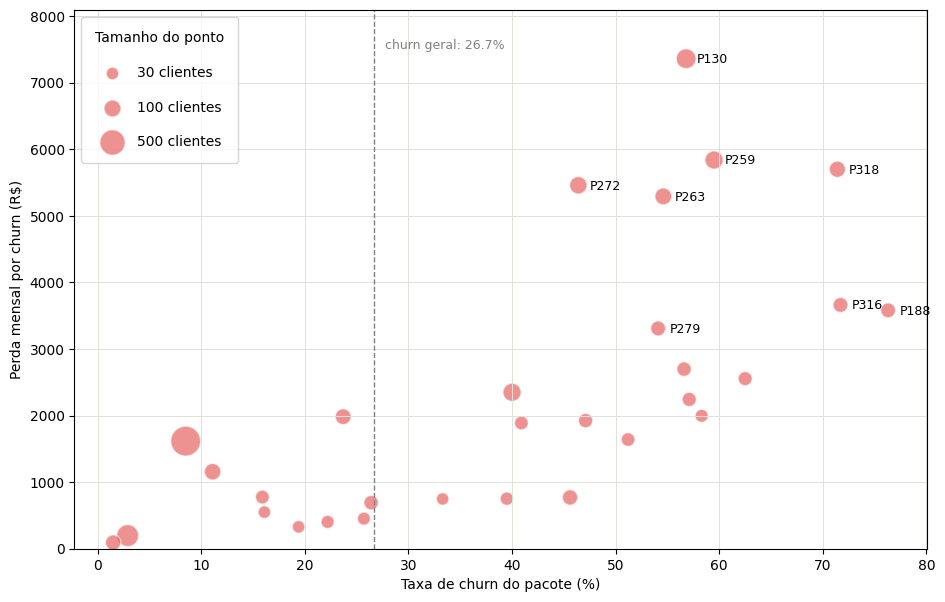

In [0]:
%python
# ============================================================
# Gráfico de perda por churn dos pacotes de serviços (history_pacotes)
# ============================================================
# O que faz: plota os pacotes com 30 ou mais clientes por taxa de churn e perda mensal de receita.
# Origem:    history_pacotes.
# Saída:     gráfico de dispersão (nada é gravado).
# Regras:    só history, porque o churn só existe nela; corte de 30 ou mais clientes por pacote.
#            eixo X = taxa de churn do pacote (%), com 1 casa; eixo Y = perda mensal (R$), soma do MonthlyCharges dos clientes com Churn = Yes.
#            Tamanho do ponto cresce com a raiz quadrada do número de clientes do pacote; a legenda mostra três tamanhos de referência (30, 100 e 500 clientes).
#            Linha tracejada: churn geral da history_pacotes, com 1 casa.
#            Código do pacote escrito só nos 8 pacotes de maior perda mensal.
#            Eixo Y começa em zero e vai até 10% acima da maior perda.
# ============================================================
import matplotlib.pyplot as plt

df = spark.sql("""
SELECT
  codigo_pacote,
  COUNT(*) AS clientes,
  CAST(ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS DOUBLE) AS taxa_churn_pct,
  CAST(ROUND(SUM(CASE WHEN Churn = 'Yes' THEN MonthlyCharges ELSE 0 END), 2) AS DOUBLE) AS perda_mensal
FROM hackaton_databricks.tabelas_hackaton.history_pacotes
GROUP BY codigo_pacote
HAVING COUNT(*) >= 30
""").toPandas()

churn_geral = float(spark.sql("""
SELECT CAST(ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS DOUBLE)
FROM hackaton_databricks.tabelas_hackaton.history_pacotes
""").collect()[0][0])

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(df["taxa_churn_pct"], df["perda_mensal"], s=15 * df["clientes"] ** 0.5,
           c="#e34948", alpha=0.6, edgecolors="white")

ax.axvline(churn_geral, color="gray", linestyle="--", linewidth=1)
ax.text(churn_geral + 1, df["perda_mensal"].max() * 1.02, f"churn geral: {churn_geral:g}%", color="gray", fontsize=9)

for _, r in df.nlargest(8, "perda_mensal").iterrows():
    ax.annotate(r["codigo_pacote"], (r["taxa_churn_pct"], r["perda_mensal"]),
                textcoords="offset points", xytext=(8, -3), fontsize=9)

for n in (30, 100, 500):
    ax.scatter([], [], s=15 * n ** 0.5, c="#e34948", alpha=0.6, edgecolors="white", label=f"{n} clientes")

ax.set_xlabel("Taxa de churn do pacote (%)")
ax.set_ylabel("Perda mensal por churn (R$)")
ax.set_ylim(0, df["perda_mensal"].max() * 1.1)
ax.grid(color="#e1e0d9", linewidth=0.7)
ax.legend(loc="upper left", title="Tamanho do ponto", labelspacing=1.5, borderpad=1)
plt.show()

**Pacotes com maior perda por churn**
P130 (185 clientes, churn 56,8%): perda de cerca de R$ 7.400 por mês, a maior.
P259 (131 clientes, 59,5%): cerca de R$ 5.850.
P318 (84 clientes, 71,4%): cerca de R$ 5.700.
P272 (112 clientes, 46,4%): cerca de R$ 5.450.
P263 (97 clientes, 54,6%): cerca de R$ 5.300.
P316 (60 clientes, 71,7%): cerca de R$ 3.650.
P188 (59 clientes, 76,3%): cerca de R$ 3.600, com o maior churn entre todos.
P279 (61 clientes, 54,1%): cerca de R$ 3.300.

**Pacotes com menor perda por churn**
P237 (68 clientes, churn 1,5%): R$ 92,45 por mês, a menor perda. É o pacote completo (9 serviços, valor médio R$ 89,98), com apenas 1 cliente cancelado.
P194 (280 clientes, 2,9%): R$ 197,20. É PhoneService + MultipleLines (valor médio R$ 24,97). Tem muitos clientes, mas churn baixo e ticket baixo.
P119 (31 clientes, 19,4%): R$ 327,95. DSL com 4 serviços (valor médio R$ 55,01), pacote pequeno.
P075 (36 clientes, 22,2%): R$ 402,30. DSL com 3 serviços (valor médio R$ 50,16).
P126 (35 clientes, 25,7%): R$ 452,05. DSL com 3 serviços (valor médio R$ 49,88).
P292 (31 clientes, 16,1%): R$ 549,40. Fiber optic com 8 serviços (valor médio R$ 110,09). O ticket alto compensa a perda baixa só em parte: 5 clientes cancelados custam mais que em pacotes baratos.
P091 (53 clientes, 26,4%): R$ 691,45. DSL com 3 serviços (valor médio R$ 49,95).
P155 (30 clientes, 33,3%): R$ 747,95. Fiber optic com 3 serviços (valor médio R$ 74,86). É o único dos 8 com churn acima do geral (26,7%).

In [0]:
%sql
-- ============================================================
-- Validação 9 – Perda total por churn e participação dos 8 pacotes de maior perda (history_pacotes)
-- ============================================================
-- O que faz: calcula a perda mensal total por churn na history e a participação dos 8 pacotes de maior perda, em perda de receita e em clientes com churn.
-- Origem:    history_pacotes.
-- Saída:     consulta de uma linha, com perda_total, perda_8_pacotes, pct_perda_8, churn_total, churn_8_pacotes e pct_churn_8 (nada é gravado).
-- Regras:    só history, porque o churn só existe nela; todos os pacotes, sem corte de número de clientes.
--            Os 8 pacotes são fixos no código: P130, P259, P318, P272, P263, P316, P188 e P279 (os de maior perda mensal, conforme a Validação 8).
--            perda_total = soma do MonthlyCharges dos clientes com Churn = Yes, em R$ por mês; perda_8_pacotes = mesma soma, só nos 8 pacotes; ambas com 2 casas.
--            pct_perda_8 = perda_8_pacotes / perda_total, em %, com 1 casa.
--            churn_total = clientes com Churn = Yes; churn_8_pacotes = os mesmos clientes, só nos 8 pacotes; pct_churn_8 = churn_8_pacotes / churn_total, em %, com 1 casa.
-- ============================================================

SELECT
  ROUND(SUM(CASE WHEN Churn = 'Yes' THEN MonthlyCharges ELSE 0 END), 2) AS perda_total,
  ROUND(SUM(CASE WHEN Churn = 'Yes' AND codigo_pacote IN ('P130','P259','P318','P272','P263','P316','P188','P279') THEN MonthlyCharges ELSE 0 END), 2) AS perda_8_pacotes,
  ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' AND codigo_pacote IN ('P130','P259','P318','P272','P263','P316','P188','P279') THEN MonthlyCharges ELSE 0 END)
        / SUM(CASE WHEN Churn = 'Yes' THEN MonthlyCharges ELSE 0 END), 1) AS pct_perda_8,
  SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churn_total,
  SUM(CASE WHEN Churn = 'Yes' AND codigo_pacote IN ('P130','P259','P318','P272','P263','P316','P188','P279') THEN 1 ELSE 0 END) AS churn_8_pacotes,
  ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' AND codigo_pacote IN ('P130','P259','P318','P272','P263','P316','P188','P279') THEN 1 ELSE 0 END)
        / SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END), 1) AS pct_churn_8
FROM hackaton_databricks.tabelas_hackaton.history_pacotes;

perda_total,perda_8_pacotes,pct_perda_8,churn_total,churn_8_pacotes,pct_churn_8
112242.90,40190.05,35.8,1504,469,31.2
